# 07. Static Link Reconstruction

This notebook answers RQ3 by hiding real edges from a static snapshot, keeping every training graph connected, sampling matched non-edges, and comparing structural and embedding scores over five fixed splits.


In [1]:
from pathlib import Path
import os
import sys
import warnings

import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, display


def find_project_root(start: Path) -> Path:
    """Find the repository root whether Jupyter starts there or in notebooks/."""
    for candidate in (start, *start.parents):
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the project root.")


ROOT = find_project_root(Path.cwd())
os.chdir(ROOT)
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

os.environ.setdefault("PYTHONHASHSEED", "0")
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
print(f"Project root: {ROOT}")


Project root: C:\Users\Jimi\Desktop\github-social-network


## Protected spanning tree and negative sampling

The essential split logic in `src/link_prediction.py` is:

```text
protected = edges of a seeded BFS spanning tree
removable = all graph edges except protected
test_positives = a seeded sample from removable
G_train = G with test_positives removed
assert G_train is connected and has no isolated nodes

for each endpoint-label stratum (Web-Web, ML-ML, Web-ML):
    sample the same number of unique pairs that are non-edges in the full graph
```

Sampling against the full graph ensures that a hidden positive is never mislabeled as a negative. The labels are used only to create matched evaluation strata, not as a reconstruction score.


### Production implementation: pair labels and connectivity protection

This first portion of src/link_prediction.py canonicalizes undirected node pairs, classifies them as same- or cross-field, and selects randomized spanning-tree edges that cannot be removed. It receives node pairs, the label mapping, or the graph and seed, and returns stable pair keys, group labels, or the protected edge set. Protecting one spanning tree per connected component preserves graph connectivity before positive edges are held out for reconstruction.


In [ ]:
"""Leakage-safe reconstruction of randomly hidden edges.

Each split protects a spanning tree, removes test positives only from the
remaining edges, and samples true non-edges with the same endpoint-label
composition as the hidden positives.  Consequently the train graph stays
connected and same-field/cross-field comparisons use identical sampling rules.
"""

from collections import Counter
import math
import random
from typing import Dict, List, Mapping, Sequence, Tuple

import networkx as nx
import numpy as np
import pandas as pd


Pair = Tuple[int, int]
EDGE_TYPES = ("Web-Web", "ML-ML", "Web-ML")


def canonical_pair(u: int, v: int) -> Pair:
    """Return an undirected pair in stable order."""
    return (int(min(u, v)), int(max(u, v)))


def edge_label_type(u: int, v: int, labels_dict: Mapping[int, int]) -> str:
    """Categorize a pair by endpoint labels."""
    label_u = labels_dict.get(int(u))
    label_v = labels_dict.get(int(v))
    if label_u == 0 and label_v == 0:
        return "Web-Web"
    if label_u == 1 and label_v == 1:
        return "ML-ML"
    if {label_u, label_v} == {0, 1}:
        return "Web-ML"
    raise ValueError(f"Missing or invalid labels for pair ({u}, {v})")


def edge_field_group(u: int, v: int, labels_dict: Mapping[int, int]) -> str:
    """Collapse endpoint labels to the research comparison."""
    return (
        "same-field"
        if labels_dict.get(int(u)) == labels_dict.get(int(v))
        else "cross-field"
    )


def _protected_spanning_tree_edges(G: nx.Graph, seed: int) -> set[Pair]:
    """Build one reproducible spanning tree and return its protected edges."""
    if G.number_of_nodes() == 0 or not nx.is_connected(G):
        raise ValueError("Connectivity-preserving splitting requires a connected graph.")
    rng = random.Random(seed)
    root = rng.choice(sorted(int(node) for node in G.nodes()))
    protected = {canonical_pair(u, v) for u, v in nx.bfs_edges(G, root)}
    if len(protected) != G.number_of_nodes() - 1:
        raise AssertionError("The protected edge set is not a spanning tree.")
    return protected



### Production implementation: stratified positive and negative edge sampling

This block reproduces the negative-pair sampler and the complete link-prediction split constructor. It receives the graph, label mapping, test fraction, and random seed, then returns a connectivity-preserving training graph plus balanced positive and negative pairs stratified by same- versus cross-field type. The attempt limits, candidate checks, protected-edge filtering, and diagnostic counts make the sampling logic auditable and prevent accidental overlap with observed edges.


In [ ]:
def _sample_negative_pairs_by_type(
    G: nx.Graph,
    labels_dict: Mapping[int, int],
    counts_by_type: Mapping[str, int],
    rng: random.Random,
) -> List[Pair]:
    """Sample true non-edges matching positive counts for every edge type."""
    web_nodes = sorted(int(node) for node in G if labels_dict.get(int(node)) == 0)
    ml_nodes = sorted(int(node) for node in G if labels_dict.get(int(node)) == 1)
    if len(web_nodes) < 2 or len(ml_nodes) < 2:
        raise ValueError("Both label groups need at least two nodes.")

    pools = {"Web-Web": web_nodes, "ML-ML": ml_nodes}
    negatives: List[Pair] = []
    seen: set[Pair] = set()

    for edge_type in EDGE_TYPES:
        target = int(counts_by_type.get(edge_type, 0))
        accepted = 0
        attempts = 0
        max_attempts = max(10_000, target * 200)
        while accepted < target:
            attempts += 1
            if attempts > max_attempts:
                raise RuntimeError(
                    f"Could not sample {target:,} unique {edge_type} non-edges."
                )

            if edge_type == "Web-ML":
                u = web_nodes[rng.randrange(len(web_nodes))]
                v = ml_nodes[rng.randrange(len(ml_nodes))]
            else:
                pool = pools[edge_type]
                u = pool[rng.randrange(len(pool))]
                v = pool[rng.randrange(len(pool))]
                if u == v:
                    continue

            pair = canonical_pair(u, v)
            if pair in seen or G.has_edge(*pair):
                continue
            seen.add(pair)
            negatives.append(pair)
            accepted += 1

    rng.shuffle(negatives)
    return negatives


def sample_link_prediction_split(
    G: nx.Graph,
    labels_dict: Mapping[int, int],
    test_fraction: float = 0.1,
    seed: int = 42,
) -> Tuple[nx.Graph, List[Pair], List[Pair], Dict[str, int | float | bool]]:
    """Create a connected train graph and label-stratified test pairs.

    The protected spanning tree makes disconnection impossible.  Negative
    examples are sampled against the full graph, so every negative is a real
    non-edge and the positive/negative count matches within Web-Web, ML-ML and
    Web-ML strata.
    """
    if not 0 < test_fraction < 1:
        raise ValueError("test_fraction must be in (0, 1).")

    rng = random.Random(seed)
    protected = _protected_spanning_tree_edges(G, seed)
    removable = [
        canonical_pair(u, v)
        for u, v in G.edges()
        if canonical_pair(u, v) not in protected
    ]
    rng.shuffle(removable)

    requested_n_test = int(round(G.number_of_edges() * test_fraction))
    n_test = min(requested_n_test, len(removable))
    if n_test <= 0:
        raise ValueError("No non-tree edges are available for testing.")
    positive_pairs = removable[:n_test]

    G_train = G.copy()
    G_train.remove_edges_from(positive_pairs)
    assert nx.is_connected(G_train)
    isolated_nodes = list(nx.isolates(G_train))
    if isolated_nodes:
        raise AssertionError(f"Split created {len(isolated_nodes)} isolated nodes.")

    positive_type_counts = Counter(
        edge_label_type(u, v, labels_dict) for u, v in positive_pairs
    )
    negative_pairs = _sample_negative_pairs_by_type(
        G=G,
        labels_dict=labels_dict,
        counts_by_type=positive_type_counts,
        rng=rng,
    )
    negative_type_counts = Counter(
        edge_label_type(u, v, labels_dict) for u, v in negative_pairs
    )
    if positive_type_counts != negative_type_counts:
        raise AssertionError("Negative sampling did not preserve edge-type counts.")

    diagnostics: Dict[str, int | float | bool] = {
        "seed": int(seed),
        "requested_test_fraction": float(test_fraction),
        "actual_test_fraction": float(n_test / G.number_of_edges()),
        "protected_tree_edges": int(len(protected)),
        "hidden_positive_edges": int(n_test),
        "negative_pairs": int(len(negative_pairs)),
        "train_nodes": int(G_train.number_of_nodes()),
        "train_edges": int(G_train.number_of_edges()),
        "train_connected": bool(nx.is_connected(G_train)),
        "isolated_nodes": int(len(isolated_nodes)),
    }
    for edge_type in EDGE_TYPES:
        key = edge_type.lower().replace("-", "_")
        diagnostics[f"positive_{key}"] = int(positive_type_counts.get(edge_type, 0))
        diagnostics[f"negative_{key}"] = int(negative_type_counts.get(edge_type, 0))

    return G_train, positive_pairs, negative_pairs, diagnostics



## Scores and train-graph-only embeddings

For every candidate pair `(u, v)`, scores are computed from `G_train`:

```text
Common Neighbors       = |N(u) ∩ N(v)|
Jaccard                 = |N(u) ∩ N(v)| / |N(u) ∪ N(v)|
Adamic-Adar             = sum(1 / log(deg(w))) for shared neighbors w
Preferential Attachment = deg(u) * deg(v)
Same Community          = 1 if Louvain_train(u) == Louvain_train(v), else 0
Embedding score         = dot(z_u, z_v)
```

For every split, Louvain, DeepWalk, and Node2Vec are trained again on `G_train` after the test edges have been removed. Hidden edges therefore cannot influence neighborhoods, communities, walks, or embeddings.


### Production implementation: reconstruction scores and evaluation

This final src/link_prediction.py block computes Common Neighbors, Jaccard, Adamic-Adar, Preferential Attachment, and embedding-dot-product scores, then evaluates them with ROC-AUC and Average Precision. It receives the training graph or embedding model and a sequence of candidate pairs, and returns aligned score lists or a metric tuple. Isolates, absent embeddings, empty evaluations, and single-class labels are handled explicitly so failed or undefined cases cannot masquerade as valid performance.


In [ ]:
def score_heuristics(
    G_train: nx.Graph,
    pairs: Sequence[Pair],
    partition: Mapping[int, int],
) -> pd.DataFrame:
    """Score pairs with course-covered structural heuristics."""
    neighbor_sets: Dict[int, set[int]] = {}

    def neighbors_of(node: int) -> set[int]:
        if node not in neighbor_sets:
            neighbor_sets[node] = (
                set(int(n) for n in G_train.neighbors(node))
                if node in G_train
                else set()
            )
        return neighbor_sets[node]

    rows = []
    for u, v in pairs:
        nbrs_u = neighbors_of(u)
        nbrs_v = neighbors_of(v)
        common = nbrs_u & nbrs_v
        union_size = len(nbrs_u | nbrs_v)
        adamic_adar = sum(
            1.0 / math.log(len(neighbors_of(w)))
            for w in common
            if len(neighbors_of(w)) > 1
        )
        rows.append(
            {
                "u": int(u),
                "v": int(v),
                "common_neighbors": int(len(common)),
                "jaccard": float(len(common) / union_size if union_size else 0.0),
                "adamic_adar": float(adamic_adar),
                "preferential_attachment": int(len(nbrs_u) * len(nbrs_v)),
                "same_community": int(
                    partition.get(int(u), -1) == partition.get(int(v), -2)
                ),
            }
        )
    return pd.DataFrame(rows)


def score_embedding_dot(w2v_model, pairs: Sequence[Pair]) -> List[float]:
    """Score a pair by the dot product of train-graph embeddings."""
    scores = []
    for u, v in pairs:
        key_u, key_v = str(int(u)), str(int(v))
        if key_u in w2v_model.wv and key_v in w2v_model.wv:
            scores.append(
                float(np.dot(w2v_model.wv[key_u], w2v_model.wv[key_v]))
            )
        else:
            scores.append(0.0)
    return scores


def auc_and_ap(
    y_true: np.ndarray, y_score: np.ndarray
) -> Tuple[float, float]:
    """Return ROC-AUC and Average Precision for a non-degenerate stratum."""
    from sklearn.metrics import average_precision_score, roc_auc_score

    if len(np.unique(y_true)) < 2:
        return float("nan"), float("nan")
    return (
        float(roc_auc_score(y_true, y_score)),
        float(average_precision_score(y_true, y_score)),
    )


In [2]:
from data_loader import load_dataset
from link_prediction import sample_link_prediction_split

G, _, _, labels_dict = load_dataset(ROOT / "data")
G_train_demo, positive_demo, negative_demo, demo_diagnostics = sample_link_prediction_split(
    G, labels_dict, test_fraction=0.01, seed=SEED
)
display(pd.DataFrame([demo_diagnostics]))
assert nx.is_connected(G_train_demo)
assert all(not G.has_edge(u, v) for u, v in negative_demo)
assert all(not G_train_demo.has_edge(u, v) for u, v in positive_demo)
del G_train_demo, positive_demo, negative_demo


,seed,requested_test_fraction,actual_test_fraction,protected_tree_edges,hidden_positive_edges,negative_pairs,train_nodes,train_edges,train_connected,isolated_nodes,positive_web_web,negative_web_web,positive_ml_ml,negative_ml_ml,positive_web_ml,negative_web_ml
0,42,0.01,0.01,37699,2890,2890,37700,286113,True,0,2269,2269,173,173,448,448


### Production implementation: reconstruction summaries and figures

This part of src/run_link_prediction.py defines the experiment constants, summary-table transformation, and the overall and same-versus-cross-field comparison plots. It receives tidy per-seed metric rows and an output path, then returns an aggregated table or writes the exact bar charts displayed below. The method order, standard-deviation error bars, axis scales, and annotations are preserved so the visual evidence matches the numerical reconstruction results.


In [ ]:
"""Connected, repeated edge-reconstruction experiment.

The task reconstructs randomly hidden edges in a static snapshot; it does not
forecast future link formation.  Every split protects a spanning tree, matches
negative examples by endpoint-label type, and recomputes Louvain, DeepWalk and
Node2Vec on the train graph only.
"""

from pathlib import Path
import sys
import time
from typing import Sequence

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SRC_DIR = Path(__file__).resolve().parent
PROJECT_DIR = SRC_DIR.parent
sys.path.insert(0, str(SRC_DIR))

from community_analysis import detect_louvain_communities
from data_loader import load_dataset
from embeddings import (
    generate_node2vec_walks,
    generate_random_walks,
    train_deepwalk,
    train_node2vec,
)
from link_prediction import (
    EDGE_TYPES,
    auc_and_ap,
    edge_field_group,
    edge_label_type,
    sample_link_prediction_split,
    score_embedding_dot,
    score_heuristics,
)


SEEDS = (42, 7, 21, 84, 123)
TEST_FRACTION = 0.10
LINK_NUM_WALKS = 2
LINK_WALK_LENGTH = 20
LINK_DIMENSIONS = 32
LINK_WINDOW = 5
LINK_EPOCHS = 3
NODE2VEC_P = 1.0
NODE2VEC_Q = 2.0

HEURISTICS = [
    ("common_neighbors", "Common Neighbors"),
    ("jaccard", "Jaccard"),
    ("adamic_adar", "Adamic-Adar"),
    ("preferential_attachment", "Preferential Attachment"),
    ("same_community", "Same Community"),
    ("deepwalk_dot", "DeepWalk"),
    ("node2vec_dot", "Node2Vec"),
]


def _summarize(
    frame: pd.DataFrame, group_columns: list[str]
) -> pd.DataFrame:
    """Aggregate mean and sample standard deviation over seeds."""
    summary = (
        frame.groupby(group_columns, as_index=False)
        .agg(
            n_positive_mean=("n_positive", "mean"),
            n_negative_mean=("n_negative", "mean"),
            roc_auc_mean=("roc_auc", "mean"),
            roc_auc_std=("roc_auc", "std"),
            average_precision_mean=("average_precision", "mean"),
            average_precision_std=("average_precision", "std"),
        )
        .sort_values(group_columns)
        .reset_index(drop=True)
    )
    return summary


def _plot_overall(summary_df: pd.DataFrame, output_path: Path) -> None:
    ordered = [name for _, name in HEURISTICS]
    plot_df = summary_df.set_index("heuristic").reindex(ordered).reset_index()
    fig, ax = plt.subplots(figsize=(11, 5.8))
    x = np.arange(len(plot_df))
    bars = ax.bar(
        x,
        plot_df["roc_auc_mean"],
        yerr=plot_df["roc_auc_std"],
        capsize=4,
        color="#315C8D",
    )
    for bar, value in zip(bars, plot_df["roc_auc_mean"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.012,
            f"{value:.3f}",
            ha="center",
            fontsize=9,
        )
    ax.axhline(0.5, color="#666666", linestyle="--", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(ordered, rotation=20, ha="right")
    ax.set_ylabel("ROC-AUC")
    ax.set_ylim(0.45, 1.02)
    ax.set_title(
        "Reconstruction of randomly hidden edges\n"
        "Mean and standard deviation across five connected splits"
    )
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def _plot_same_cross(summary_df: pd.DataFrame, output_path: Path) -> None:
    ordered = [name for _, name in HEURISTICS]
    x = np.arange(len(ordered))
    width = 0.36
    colors = {"same-field": "#315C8D", "cross-field": "#D57837"}
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), sharex=True)
    for ax, metric, label in (
        (axes[0], "roc_auc_mean", "ROC-AUC"),
        (axes[1], "average_precision_mean", "Average Precision"),
    ):
        for offset, group in ((-width / 2, "same-field"), (width / 2, "cross-field")):
            values = (
                summary_df[summary_df["edge_group"] == group]
                .set_index("heuristic")
                .reindex(ordered)[metric]
                .to_numpy()
            )
            ax.bar(
                x + offset,
                values,
                width,
                label=group,
                color=colors[group],
            )
        ax.axhline(0.5, color="#666666", linestyle="--", linewidth=1)
        ax.set_title(label)
        ax.set_ylim(0.45, 1.02)
        ax.grid(axis="y", alpha=0.25)
        ax.set_xticks(x)
        ax.set_xticklabels(ordered, rotation=24, ha="right")
    axes[0].set_ylabel("Score")
    axes[1].legend(title="Hidden-edge group", loc="lower right")
    fig.suptitle(
        "Direct same-field versus cross-field reconstruction\n"
        "Matched positive and negative counts within every endpoint-label stratum"
    )
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)



### Production implementation: five-seed link-reconstruction experiment

This block is the main workflow from src/run_link_prediction.py. For each random state it builds a protected split, learns DeepWalk only on the training graph, scores every heuristic and embedding method overall and by edge type, and saves diagnostics, summaries, field gaps, and figures. Its inputs are the configured graph data and seed sequence; its outputs are the complete reconstruction artifacts used to test whether network structure recovers held-out mutual-follow links.


In [ ]:
def main(random_states: Sequence[int] = SEEDS) -> None:
    data_dir = PROJECT_DIR / "data"
    tables_dir = PROJECT_DIR / "outputs" / "tables"
    figures_dir = PROJECT_DIR / "outputs" / "figures"
    tables_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)

    G, _, _, labels_dict = load_dataset(data_dir)
    overall_rows: list[dict] = []
    type_rows: list[dict] = []
    group_rows: list[dict] = []
    diagnostic_rows: list[dict] = []

    for run_idx, seed in enumerate(random_states, start=1):
        started = time.time()
        print(f"[edge split {run_idx}/{len(random_states)}] seed={seed}")
        G_train, positive_pairs, negative_pairs, diagnostics = (
            sample_link_prediction_split(
                G,
                labels_dict=labels_dict,
                test_fraction=TEST_FRACTION,
                seed=int(seed),
            )
        )
        diagnostics["run"] = int(run_idx)
        diagnostic_rows.append(diagnostics)
        print(
            f"  hidden={len(positive_pairs):,}; train_connected="
            f"{diagnostics['train_connected']}; isolated={diagnostics['isolated_nodes']}"
        )

        partition, _ = detect_louvain_communities(
            G_train, random_state=int(seed)
        )

        deepwalk_walks = generate_random_walks(
            G_train,
            num_walks=LINK_NUM_WALKS,
            walk_length=LINK_WALK_LENGTH,
            seed=int(seed),
        )
        deepwalk_model = train_deepwalk(
            deepwalk_walks,
            dimensions=LINK_DIMENSIONS,
            window=LINK_WINDOW,
            epochs=LINK_EPOCHS,
            seed=int(seed),
        )
        del deepwalk_walks

        node2vec_walks = generate_node2vec_walks(
            G_train,
            num_walks=LINK_NUM_WALKS,
            walk_length=LINK_WALK_LENGTH,
            p=NODE2VEC_P,
            q=NODE2VEC_Q,
            seed=int(seed),
        )
        node2vec_model = train_node2vec(
            node2vec_walks,
            dimensions=LINK_DIMENSIONS,
            window=LINK_WINDOW,
            epochs=LINK_EPOCHS,
            seed=int(seed),
        )
        del node2vec_walks

        positive_scores = score_heuristics(
            G_train, positive_pairs, partition
        )
        negative_scores = score_heuristics(
            G_train, negative_pairs, partition
        )
        positive_scores["deepwalk_dot"] = score_embedding_dot(
            deepwalk_model, positive_pairs
        )
        negative_scores["deepwalk_dot"] = score_embedding_dot(
            deepwalk_model, negative_pairs
        )
        positive_scores["node2vec_dot"] = score_embedding_dot(
            node2vec_model, positive_pairs
        )
        negative_scores["node2vec_dot"] = score_embedding_dot(
            node2vec_model, negative_pairs
        )
        positive_scores["is_edge"] = 1
        negative_scores["is_edge"] = 0
        scores_df = pd.concat(
            [positive_scores, negative_scores], ignore_index=True
        )
        scores_df["edge_type"] = [
            edge_label_type(u, v, labels_dict)
            for u, v in zip(scores_df["u"], scores_df["v"])
        ]
        scores_df["edge_group"] = [
            edge_field_group(u, v, labels_dict)
            for u, v in zip(scores_df["u"], scores_df["v"])
        ]

        for score_column, heuristic_name in HEURISTICS:
            auc, ap = auc_and_ap(
                scores_df["is_edge"].to_numpy(),
                scores_df[score_column].to_numpy(dtype=np.float64),
            )
            overall_rows.append(
                {
                    "run": int(run_idx),
                    "random_state": int(seed),
                    "heuristic": heuristic_name,
                    "n_positive": int(scores_df["is_edge"].sum()),
                    "n_negative": int((1 - scores_df["is_edge"]).sum()),
                    "roc_auc": auc,
                    "average_precision": ap,
                }
            )

            for edge_type in EDGE_TYPES:
                subset = scores_df[scores_df["edge_type"] == edge_type]
                auc_t, ap_t = auc_and_ap(
                    subset["is_edge"].to_numpy(),
                    subset[score_column].to_numpy(dtype=np.float64),
                )
                type_rows.append(
                    {
                        "run": int(run_idx),
                        "random_state": int(seed),
                        "heuristic": heuristic_name,
                        "edge_type": edge_type,
                        "n_positive": int(subset["is_edge"].sum()),
                        "n_negative": int((1 - subset["is_edge"]).sum()),
                        "roc_auc": auc_t,
                        "average_precision": ap_t,
                    }
                )

            for edge_group in ("same-field", "cross-field"):
                subset = scores_df[scores_df["edge_group"] == edge_group]
                auc_g, ap_g = auc_and_ap(
                    subset["is_edge"].to_numpy(),
                    subset[score_column].to_numpy(dtype=np.float64),
                )
                group_rows.append(
                    {
                        "run": int(run_idx),
                        "random_state": int(seed),
                        "heuristic": heuristic_name,
                        "edge_group": edge_group,
                        "n_positive": int(subset["is_edge"].sum()),
                        "n_negative": int((1 - subset["is_edge"]).sum()),
                        "roc_auc": auc_g,
                        "average_precision": ap_g,
                    }
                )
        print(f"  completed in {time.time() - started:.1f}s")

    overall_df = pd.DataFrame(overall_rows)
    type_df = pd.DataFrame(type_rows)
    group_df = pd.DataFrame(group_rows)
    diagnostics_df = pd.DataFrame(diagnostic_rows).sort_values("run")

    overall_summary = _summarize(overall_df, ["heuristic"])
    type_summary = _summarize(type_df, ["heuristic", "edge_type"])
    group_summary = _summarize(group_df, ["heuristic", "edge_group"])

    group_pivot = group_summary.pivot(
        index="heuristic", columns="edge_group"
    )
    gaps_df = pd.DataFrame(
        {
            "heuristic": group_pivot.index,
            "roc_auc_same_minus_cross": (
                group_pivot[("roc_auc_mean", "same-field")]
                - group_pivot[("roc_auc_mean", "cross-field")]
            ),
            "average_precision_same_minus_cross": (
                group_pivot[("average_precision_mean", "same-field")]
                - group_pivot[("average_precision_mean", "cross-field")]
            ),
        }
    ).reset_index(drop=True)

    outputs = {
        "edge_reconstruction_results.csv": overall_df,
        "edge_reconstruction_summary.csv": overall_summary,
        "edge_reconstruction_by_type.csv": type_df,
        "edge_reconstruction_by_type_summary.csv": type_summary,
        "edge_reconstruction_same_vs_cross.csv": group_df,
        "edge_reconstruction_same_vs_cross_summary.csv": group_summary,
        "edge_reconstruction_same_vs_cross_gaps.csv": gaps_df,
        "edge_split_diagnostics.csv": diagnostics_df,
    }
    for filename, frame in outputs.items():
        frame.to_csv(tables_dir / filename, index=False)

    _plot_overall(
        overall_summary, figures_dir / "edge_reconstruction_auc.png"
    )
    _plot_same_cross(
        group_summary,
        figures_dir / "edge_reconstruction_same_vs_cross.png",
    )

    print("\nOverall reconstruction summary:")
    print(
        overall_summary[
            ["heuristic", "roc_auc_mean", "roc_auc_std",
             "average_precision_mean", "average_precision_std"]
        ].to_string(index=False)
    )
    print("\nSame-field minus cross-field gaps:")
    print(gaps_df.to_string(index=False))



## Run the five reconstruction splits


In [3]:
from run_link_prediction import main as run_link_prediction

run_link_prediction()


[edge split 1/5] seed=42


  hidden=28,900; train_connected=True; isolated=0


  completed in 99.0s
[edge split 2/5] seed=7


  hidden=28,900; train_connected=True; isolated=0


  completed in 96.7s
[edge split 3/5] seed=21


...

  hidden=28,900; train_connected=True; isolated=0


  completed in 99.9s
[edge split 5/5] seed=123


  hidden=28,900; train_connected=True; isolated=0


  completed in 98.2s



Overall reconstruction summary:
              heuristic  roc_auc_mean  roc_auc_std  average_precision_mean  average_precision_std
            Adamic-Adar      0.860359     0.002658                0.869723               0.002457
       Common Neighbors      0.852613     0.002758                0.848178               0.002769
               DeepWalk      0.896513     0.002614                0.906930               0.002277
                Jaccard      0.796064     0.003765                0.712517               0.005696
               Node2Vec      0.900278     0.002775                0.910573               0.002363
Preferential Attachment      0.923876     0.001096                0.931209               0.001347
         Same Community      0.704073     0.004271                0.656732               0.003613

Same-field minus cross-field gaps:
              heuristic  roc_auc_same_minus_cross  average_precision_same_minus_cross
            Adamic-Adar                  0.036923            

## Results


,seed,requested_test_fraction,actual_test_fraction,protected_tree_edges,hidden_positive_edges,negative_pairs,train_nodes,train_edges,train_connected,isolated_nodes,positive_web_web,negative_web_web,positive_ml_ml,negative_ml_ml,positive_web_ml,negative_web_ml,run
0,42,0.1,0.099999,37699,28900,28900,37700,260103,True,0,22727,22727,1907,1907,4266,4266,1
1,7,0.1,0.099999,37699,28900,28900,37700,260103,True,0,22876,22876,1828,1828,4196,4196,2
2,21,0.1,0.099999,37699,28900,28900,37700,260103,True,0,22838,22838,1788,1788,4274,4274,3
3,84,0.1,0.099999,37699,28900,28900,37700,260103,True,0,22678,22678,1983,1983,4239,4239,4
4,123,0.1,0.099999,37699,28900,28900,37700,260103,True,0,22693,22693,1875,1875,4332,4332,5


,heuristic,n_positive_mean,n_negative_mean,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
5,Preferential Attachment,28900.0,28900.0,0.9239,0.0011,0.9312,0.0013
4,Node2Vec,28900.0,28900.0,0.9003,0.0028,0.9106,0.0024
2,DeepWalk,28900.0,28900.0,0.8965,0.0026,0.9069,0.0023
0,Adamic-Adar,28900.0,28900.0,0.8604,0.0027,0.8697,0.0025
1,Common Neighbors,28900.0,28900.0,0.8526,0.0028,0.8482,0.0028
3,Jaccard,28900.0,28900.0,0.7961,0.0038,0.7125,0.0057
6,Same Community,28900.0,28900.0,0.7041,0.0043,0.6567,0.0036


,heuristic,edge_group,n_positive_mean,n_negative_mean,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
0,Adamic-Adar,cross-field,4261.4,4261.4,0.8294,0.0077,0.8367,0.0072
1,Adamic-Adar,same-field,24638.6,24638.6,0.8664,0.0027,0.8759,0.0025
2,Common Neighbors,cross-field,4261.4,4261.4,0.8241,0.0079,0.8197,0.0080
3,Common Neighbors,same-field,24638.6,24638.6,0.8583,0.0028,0.8540,0.0029
4,DeepWalk,cross-field,4261.4,4261.4,0.9016,0.0037,0.9131,0.0027
5,DeepWalk,same-field,24638.6,24638.6,0.8973,0.0025,0.9074,0.0023
6,Jaccard,cross-field,4261.4,4261.4,0.7969,0.0090,0.7408,0.0130
7,Jaccard,same-field,24638.6,24638.6,0.7955,0.0040,0.7077,0.0059
8,Node2Vec,cross-field,4261.4,4261.4,0.9040,0.0028,0.9158,0.0025
9,Node2Vec,same-field,24638.6,24638.6,0.9012,0.0028,0.9111,0.0024


,heuristic,roc_auc_same_minus_cross,average_precision_same_minus_cross
0,Adamic-Adar,0.0369,0.0392
1,Common Neighbors,0.0343,0.0343
2,DeepWalk,-0.0043,-0.0057
3,Jaccard,-0.0014,-0.0331
4,Node2Vec,-0.0027,-0.0047
5,Preferential Attachment,0.0082,0.0079
6,Same Community,-0.0093,-0.0227


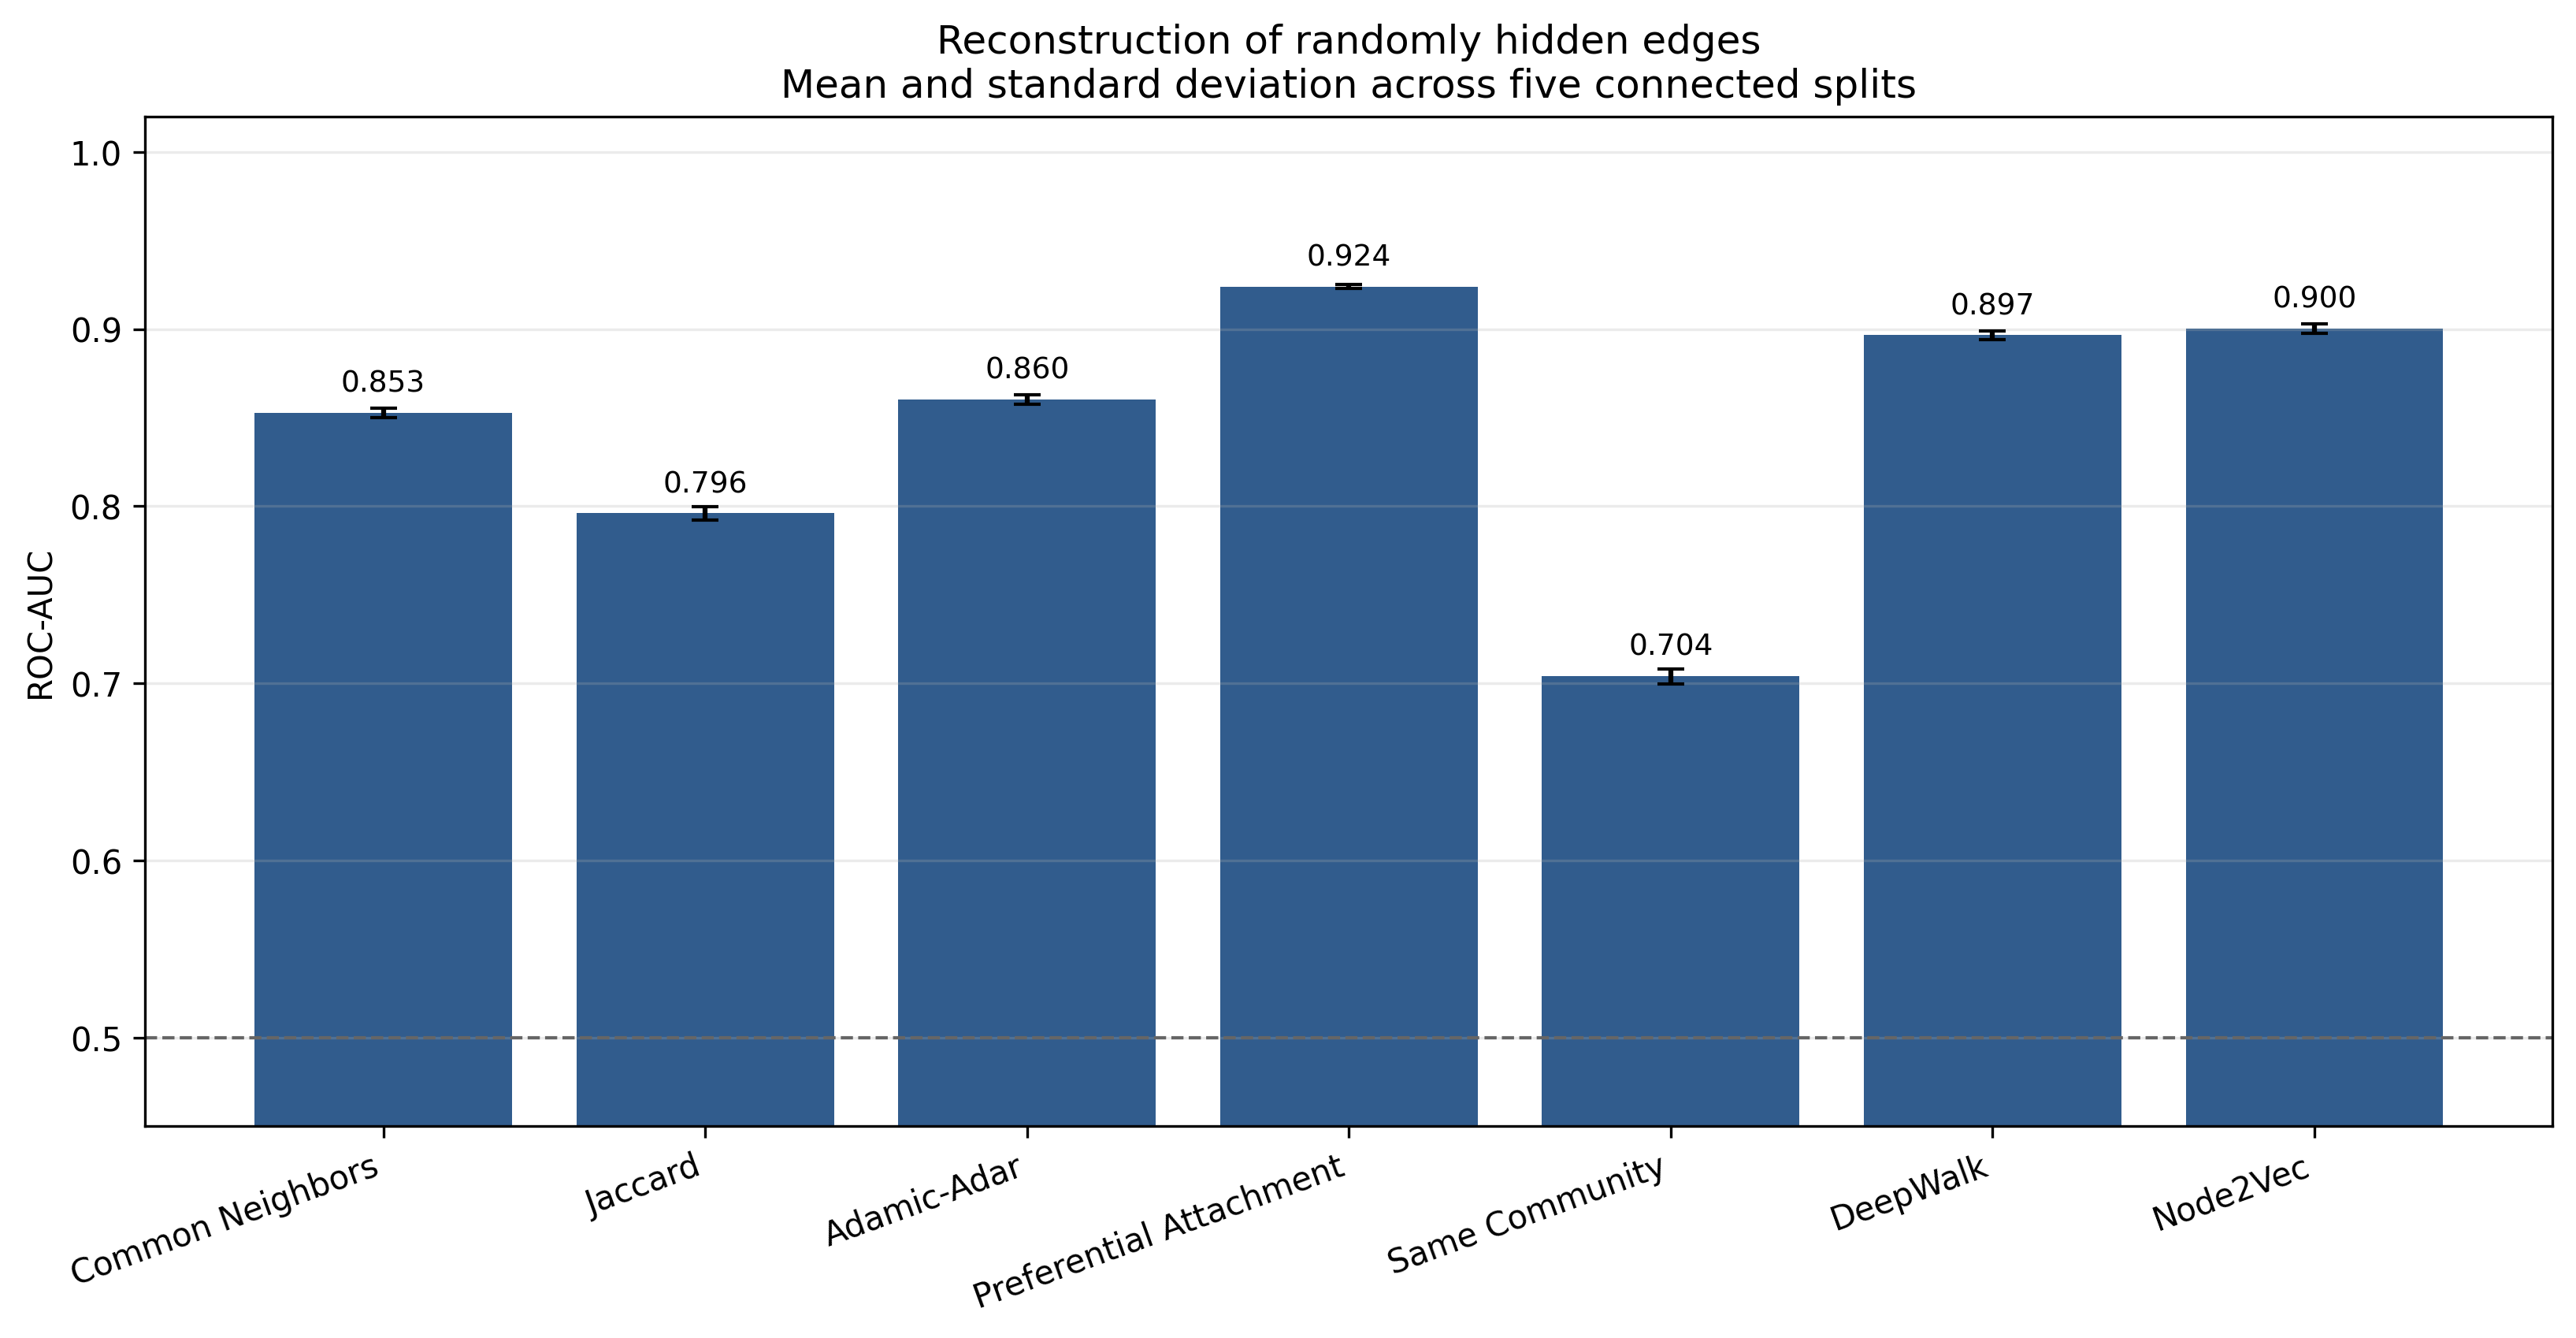

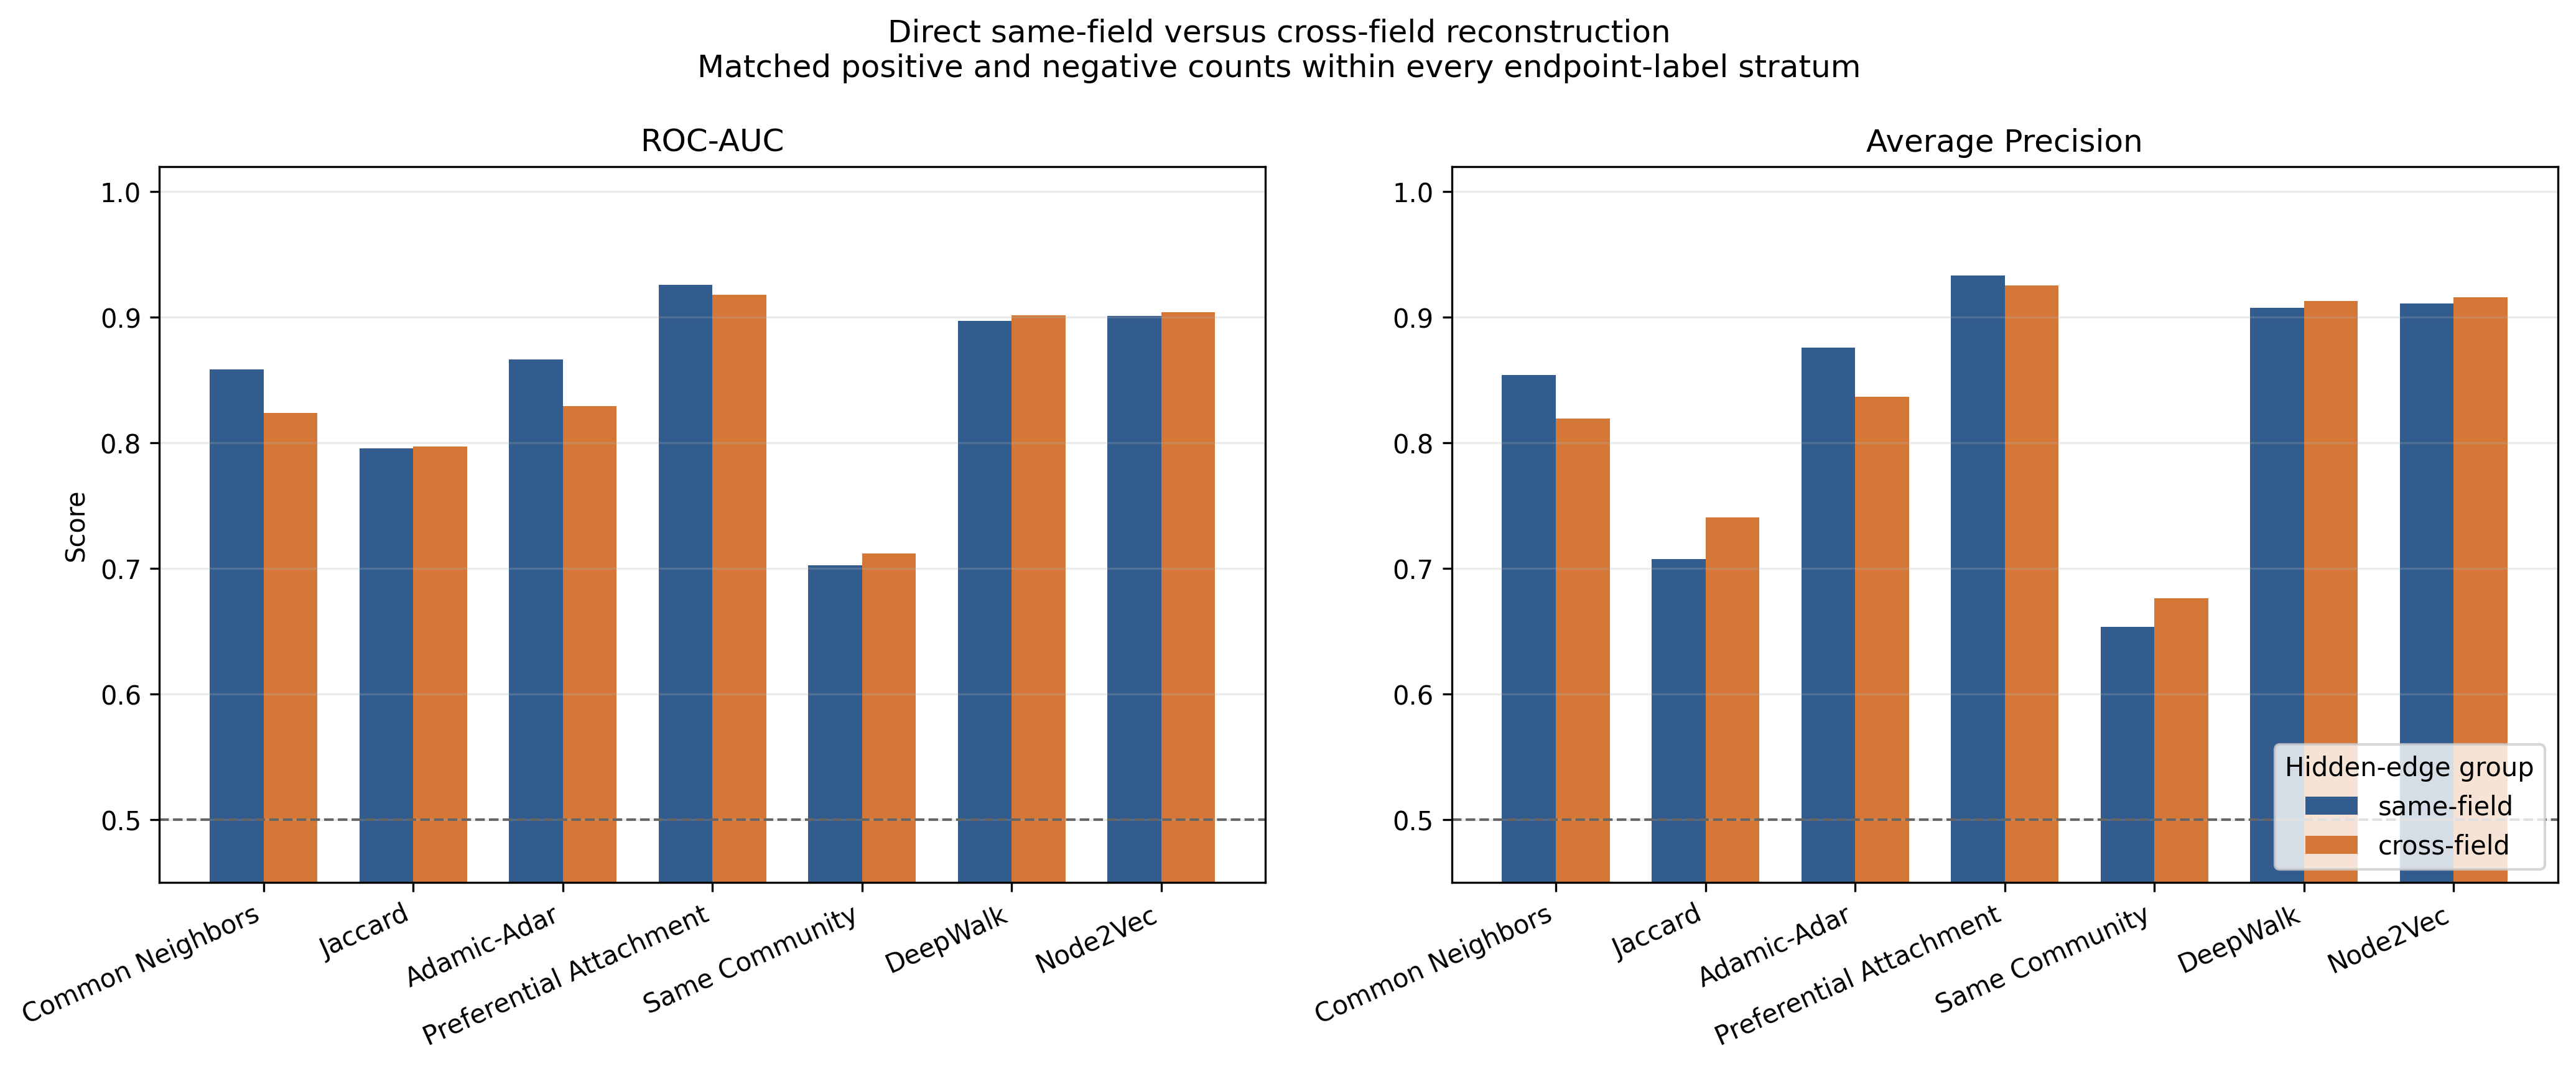

In [4]:
split_checks = pd.read_csv(ROOT / "outputs/tables/edge_split_diagnostics.csv")
link_summary = pd.read_csv(ROOT / "outputs/tables/edge_reconstruction_summary.csv")
edge_groups = pd.read_csv(ROOT / "outputs/tables/edge_reconstruction_same_vs_cross_summary.csv")
gaps = pd.read_csv(ROOT / "outputs/tables/edge_reconstruction_same_vs_cross_gaps.csv")

display(split_checks)
display(link_summary.sort_values("roc_auc_mean", ascending=False).round(4))
display(edge_groups.round(4))
display(gaps.round(4))
display(Image(filename=str(ROOT / "outputs/figures/edge_reconstruction_auc.png")))
display(Image(filename=str(ROOT / "outputs/figures/edge_reconstruction_same_vs_cross.png")))


Preferential Attachment is strongest overall, with mean ROC-AUC near 0.924. The same-field advantage is method-dependent rather than universal. This experiment reconstructs randomly hidden edges in one snapshot; it does not forecast future links.

## Limitation of the negative sample

Uniform random non-edges are often far apart and may have low-degree endpoints. This can make the task easier and may favor degree-based methods such as Preferential Attachment. Degree-matched negatives or distance-two negatives would provide a harder evaluation by comparing hidden edges with more plausible candidate pairs.

## Summary

This Notebook reconstructed randomly hidden edges over five fixed splits. Each split removed 28,900 real edges, sampled 28,900 matched non-edges by Web-Web, ML-ML, and Web-ML strata, and protected a spanning tree so the 37,700-node training graph remained connected with 260,103 edges and no isolates.

Preferential Attachment was the strongest method, with mean ROC-AUC 0.9239 and Average Precision 0.9312. Node2Vec followed at 0.9003 ROC-AUC, DeepWalk at 0.8965, Adamic-Adar at 0.8604, Common Neighbors at 0.8526, Jaccard at 0.7961, and Same Community at 0.7041. The low standard deviations showed that this ordering was stable across splits.

A same-field advantage was not universal. Adamic-Adar and Common Neighbors had same-minus-cross ROC-AUC gaps of 0.0369 and 0.0343, but DeepWalk, Node2Vec, Jaccard, and Same Community had small negative gaps; field composition therefore affected methods differently.

The result demonstrates strong static edge reconstruction under the selected evaluation design, not future-link forecasting. Uniform random non-edges may be easier than plausible distance-two or degree-matched candidates and may favor degree-based Preferential Attachment, so the saved diagnostics, summaries, group comparisons, and figures must be interpreted with that limitation.
